# relay_l2id_compare — four-arm head-to-head

Ingests the `relay_l2id_compare` sweep and compares the four relay designs on a
**moving** NR-V2X mode-2 SB-SPS platoon, using the **same metric definitions** as
`results_relay_storm_eval` so the numbers line up with the storm campaign.

**Arms:** `none` (1-hop, fixed MCS) · `none_adapt` (1-hop, worst-RX adaptive MCS) ·
`sameL2` (shared-L2ID, the storm) · `fixed` (distinct-L2ID strict partition) ·
`broadcast` (distinct-L2ID, no hop-2 HARQ). Relay positions 4 (front) and 6 (tail).

**Hypotheses tested**

| | Claim | Readout |
|---|---|---|
| H1 | distinct-L2ID removes the feedback storm | hop-1 retx ratio vs MCD ≈ 1, flat (Fig 1) |
| H2 | tail benefit is retained | tail-PRR vs MCD (Fig 2) |
| H3 | leader relaxation lowers total cost | occupancy ratio vs MCD (Fig 3) |
| H4 | distinct-L2ID trades storm for RB collision | front-PRR + leader↔relay collision (Fig 4) |
| H5 | broadcast = lowest hop-2 cost, no safety net | appears across Figs 1–4 |

**Usage:** set `RESULTS_DIR` below to your sweep output, then *Run All*. Built from
`../../DISTINCT_L2ID_EXPERIMENT_DESIGN.md`.

In [ ]:
import os, glob, sqlite3
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# One or more result directories produced by run_*.sh.  Each *_summary.csv
# is parsed exactly once and the rows are concatenated; duplicate configs
# across dirs are kept (they come from independent sweep sweeps) so the
# notebook faithfully reports the joint sample.  Override with the
# L2ID_RESULTS env var (colon-separated on POSIX).
_default_dirs = [
    "/Users/hadih/Documents/groupcast-adaptation-ns3/results_quick",
    "/Users/hadih/Documents/groupcast-adaptation-ns3/results_c4",
    "/Users/hadih/Documents/groupcast-adaptation-ns3/results_gen",
]
_env = os.environ.get("L2ID_RESULTS")
RESULTS_DIRS = _env.split(":") if _env else _default_dirs
RESULTS_DIRS = [d for d in RESULTS_DIRS if os.path.isdir(d)]

N_FOLLOWERS_DEFAULT = 8          # 9-UE platoon -> followers 1..8
NOMINAL_BOUNDARY    = 4          # front/tail split for the no-relay arms
print("RESULTS_DIRS =", [os.path.abspath(d) for d in RESULTS_DIRS])

RESULTS_DIR = /Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/relay_l2id_compare/results_quick


In [2]:
def _conn(p):
    c = sqlite3.connect(p); c.row_factory = sqlite3.Row; return c

def _cols(conn, t):
    try:
        return {r[1] for r in conn.execute("PRAGMA table_info(%s)" % t)}
    except Exception:
        return set()

def compute_kpis(db, relay_node):
    """KPIs for one run DB. relay_node = 4/6 for relay arms, -1 for no-relay.
    Mirrors agg_fixed_sweep.py, with two cross-mode fixes:
      * effective-PRR denominator = leader's generated CAM count (works for the
        partitioned 'fixed' arm, where the leader has no tail rows);
      * leader<->relay RB-overlap collision rate (H4)."""
    conn = _conn(db)
    k = dict(storm_ratio=np.nan, hop1_retx=np.nan, ch_occ=np.nan, coll_rate=np.nan,
             harq_nack=np.nan, prr_mean=np.nan, prr_worst=np.nan,
             prr_front=np.nan, prr_tail=np.nan, aoi_mean_ms=np.nan, psr=np.nan)
    try:
        tx = conn.execute("SELECT * FROM psschTxUeMac").fetchall()
        cols = _cols(conn, "psschTxUeMac")
        if tx:
            n_new = sum(1 for r in tx if r["ndi"] == 1)
            n_re  = sum(1 for r in tx if r["ndi"] == 0)
            k["storm_ratio"] = n_re / n_new if n_new else 0.0
            leader_l2 = min(r["srcL2Id"] for r in tx)
            k["hop1_retx"] = float(sum(1 for r in tx
                                       if r["srcL2Id"] == leader_l2 and r["ndi"] == 0))
            tmax = max((r["timeMs"] for r in tx), default=1.0) or 1.0
            k["ch_occ"] = len(tx) / tmax
            # leader<->relay RB-overlap collision rate (only meaningful w/ a relay)
            if {"frame", "subFrame", "slot", "rbStart", "rbLen"} <= cols:
                lead  = [r for r in tx if r["srcL2Id"] == leader_l2]
                rel   = [r for r in tx if r["srcL2Id"] != leader_l2]
                rslot = defaultdict(list)
                for r in rel:
                    rslot[(r["frame"], r["subFrame"], r["slot"])].append(
                        (r["rbStart"], r["rbStart"] + r["rbLen"]))
                if lead and rel:
                    coll = 0
                    for r in lead:
                        a0 = r["rbStart"]; a1 = a0 + r["rbLen"]
                        for b0, b1 in rslot.get((r["frame"], r["subFrame"], r["slot"]), ()):
                            if a0 < b1 and b0 < a1:
                                coll += 1; break
                    k["coll_rate"] = coll / len(lead)

        fb = conn.execute("SELECT status FROM slHarqFeedback").fetchall()
        if fb:
            k["harq_nack"] = sum(1 for r in fb if r["status"] == "NACK") / len(fb)

        gen = conn.execute("SELECT COUNT(DISTINCT pktSeqNum) FROM pktTxRx "
                           "WHERE nodeId=0 AND txRx='tx'").fetchone()[0] or 0
        relay_ip = None
        if relay_node is not None and relay_node >= 1:
            ri = conn.execute("SELECT ip FROM nodeInfo WHERE nodeId=?",
                              (relay_node,)).fetchone()
            relay_ip = ri["ip"] if ri else None
        th = conn.execute("SELECT nodeId, srcIp, totalPktTxed, totalPktRxed "
                          "FROM thput").fetchall()
        nodeids = sorted({r["nodeId"] for r in th if r["nodeId"] > 0})
        prr = {}
        for nid in nodeids:
            lrow = next((r for r in th if r["nodeId"] == nid
                         and str(r["srcIp"]).endswith(".2")), None)
            rrow = next((r for r in th if r["nodeId"] == nid
                         and r["srcIp"] == relay_ip), None) if relay_ip else None
            eff = max((lrow["totalPktRxed"] if lrow else 0),
                      (rrow["totalPktRxed"] if rrow else 0))
            prr[nid] = (eff / gen) if gen > 0 else np.nan
        if prr:
            k["prr_mean"]  = float(np.nanmean(list(prr.values())))
            k["prr_worst"] = float(np.nanmin(list(prr.values())))
            b = relay_node if (relay_node and relay_node >= 1) else NOMINAL_BOUNDARY
            front = [v for n, v in prr.items() if n <= b]
            tail  = [v for n, v in prr.items() if n >  b]
            k["prr_front"] = float(np.nanmean(front)) if front else np.nan
            k["prr_tail"]  = float(np.nanmean(tail))  if tail  else np.nan

        if relay_node is not None and relay_node >= 1 and gen > 0:
            fwd = conn.execute("SELECT COUNT(DISTINCT seq) FROM relayTiming "
                               "WHERE forwarded=1").fetchone()[0] or 0
            k["psr"] = fwd / gen

        # AoI: earliest rx minus tx, per (node, seq), in ms
        txt = {r["pktSeqNum"]: r["timeSec"] for r in conn.execute(
            "SELECT timeSec, pktSeqNum FROM pktTxRx WHERE txRx='tx'")}
        if txt:
            seen = {}
            for r in conn.execute(
                "SELECT p.timeSec AS rt, p.pktSeqNum AS sq, p.nodeId AS nd "
                "FROM pktTxRx p WHERE p.txRx='rx' AND p.nodeId>0 ORDER BY p.pktSeqNum"):
                key = (r["nd"], r["sq"])
                if key not in seen and r["sq"] in txt and r["rt"] >= txt[r["sq"]]:
                    seen[key] = (r["rt"] - txt[r["sq"]]) * 1000.0
            if seen:
                k["aoi_mean_ms"] = float(np.mean(list(seen.values())))
    finally:
        conn.close()
    return k

print("compute_kpis ready")

compute_kpis ready


In [3]:
def arm_of(relay_mode, adaptive):
    if relay_mode == "none":
        return "none_adapt" if adaptive else "none"
    return relay_mode

rows = []
for RESULTS_DIR in RESULTS_DIRS:
    summaries = glob.glob(os.path.join(RESULTS_DIR, "**", "*_summary.csv"), recursive=True)
    print(f"{RESULTS_DIR}: {len(summaries)} run summaries")
    for s in summaries:
        try:
            p = pd.read_csv(s).iloc[0].to_dict()
        except Exception as e:
            print("skip", s, e); continue
        db = os.path.join(os.path.dirname(s), str(p["runId"]) + ".db")
        if not os.path.exists(db):
            cand = glob.glob(os.path.join(os.path.dirname(s), "*.db"))
            if not cand:
                continue
            db = cand[0]
        rn = int(p.get("relayNode", -1))
        adaptive = str(p.get("adaptiveMcs", "false")).lower() == "true"
        k = compute_kpis(db, rn)
        rows.append(dict(
            source=os.path.basename(RESULTS_DIR.rstrip("/")),
            arm=arm_of(str(p["relayMode"]), adaptive),
            relayMode=str(p["relayMode"]), relayNode=rn, adaptiveMcs=adaptive,
            numUEs=int(p.get("numUEs", 9)),
            scenario=str(p.get("scenario", "V2V_Highway")),
            speed=float(p["speedKmh"]), ivd=float(p["ivd"]),
            mcd=float(p["mcdMeters"]),
            seed=int(p["seed"]), **k))

df = pd.DataFrame(rows)
if not df.empty:
    df.to_csv(os.path.join(RESULTS_DIRS[0], "l2id_compare_runs.csv"), index=False)
    print("runs:", len(df), "| arms:", sorted(df.arm.unique()),
          "| MCD:", sorted(df.mcd.unique()),
          "| sources:", sorted(df.source.unique()))
else:
    print("No runs parsed yet. Build + run the sweep, then re-run this notebook.")
df.head()

found 0 run summaries
No runs parsed yet. Build + run the sweep, then re-run this notebook.


""


## Aggregate over seeds and reference each arm to the `none` baseline

`storm_ratio_hop1` = arm hop-1 retx ÷ `none` hop-1 retx (matched speed/ivd/mcd) —
the same definition as `storm_indicator.csv`. `occ_ratio` and the PRR deltas are
likewise taken against the `none` baseline.

In [4]:
KEYS = ["arm", "relayNode", "mcd", "speed", "ivd", "scenario", "numUEs"]
METRICS = ["hop1_retx", "ch_occ", "coll_rate", "harq_nack", "storm_ratio",
           "prr_mean", "prr_worst", "prr_front", "prr_tail", "aoi_mean_ms", "psr"]

if not df.empty:
    agg = df.groupby(KEYS, dropna=False)[METRICS].mean().reset_index()
    base = (df[df.arm == "none"]
            .groupby(["speed", "ivd", "mcd", "scenario", "numUEs"])
            [["hop1_retx", "ch_occ", "prr_worst",
              "prr_tail", "prr_front", "aoi_mean_ms"]]
            .mean().reset_index()
            .rename(columns={c: "b_" + c for c in
                             ["hop1_retx", "ch_occ", "prr_worst", "prr_tail",
                              "prr_front", "aoi_mean_ms"]}))
    agg = agg.merge(base, on=["speed", "ivd", "mcd", "scenario", "numUEs"], how="left")
    agg["storm_ratio_hop1"] = agg.hop1_retx / agg.b_hop1_retx
    agg["occ_ratio"]        = agg.ch_occ   / agg.b_ch_occ
    agg["d_prr_worst"]      = agg.prr_worst - agg.b_prr_worst
    agg["d_prr_tail"]       = agg.prr_tail  - agg.b_prr_tail
    agg["d_prr_front"]      = agg.prr_front - agg.b_prr_front
    agg["d_aoi"]            = agg.aoi_mean_ms - agg.b_aoi_mean_ms
    out_csv = (RESULTS_DIRS[0] if RESULTS_DIRS
               else os.path.expanduser("~"))
    agg.to_csv(os.path.join(out_csv, "l2id_compare_aggregate.csv"), index=False)
    print("aggregate rows:", len(agg), "| scenarios:", sorted(agg.scenario.unique()))
else:
    agg = pd.DataFrame()
agg.head()

""


In [5]:
# Plot helper: mean of a column over operating points, vs MCD, one line per arm/pos.
ARM_ORDER = ["none", "none_adapt", "sameL2", "fixed", "broadcast"]
def arm_pos_label(a, rn):
    return a if a in ("none", "none_adapt") else "%s@%d" % (a, int(rn))

def line_by_arm(ax, col, ylabel, title, hline=None):
    if agg.empty:
        ax.set_title(title + " (no data)"); return
    for a in ARM_ORDER:
        sub = agg[agg.arm == a]
        for rn, g in sub.groupby("relayNode"):
            gg = g.groupby("mcd")[col].mean().sort_index()
            if gg.notna().any():
                ax.plot(gg.index, gg.values, marker="o", label=arm_pos_label(a, rn))
    if hline is not None:
        ax.axhline(hline, ls="--", c="grey", lw=1)
    ax.set_xlabel("MCD (m)"); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.legend(fontsize=8); ax.grid(alpha=.3)
print("plot helper ready")

plot helper ready


### Fig 1 — H1: does distinct-L2ID remove the storm?
`sameL2` should climb with MCD; `fixed`/`broadcast` should sit flat at ≈ 1.0.

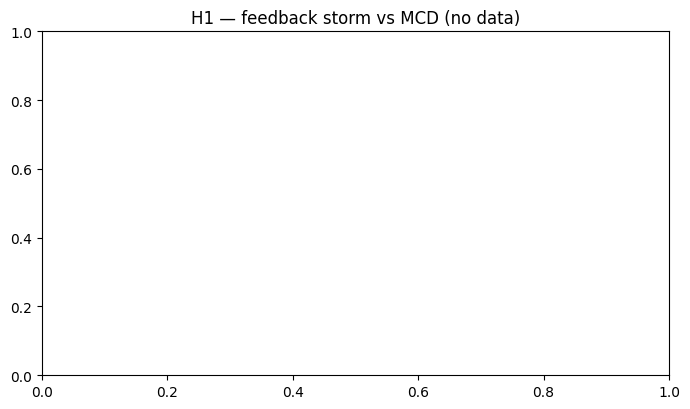

In [6]:
fig, ax = plt.subplots(figsize=(7,4.2))
line_by_arm(ax, "storm_ratio_hop1", "hop-1 retx ratio (arm / none)",
            "H1 — feedback storm vs MCD", hline=1.0)
plt.tight_layout(); plt.show()

### Fig 2 — H2: is the tail benefit retained?

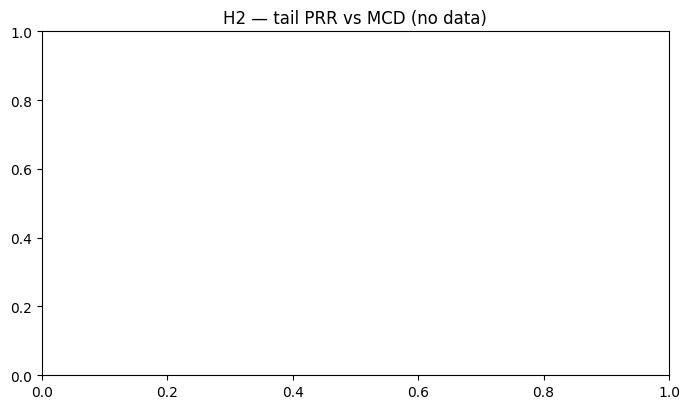

In [7]:
fig, ax = plt.subplots(figsize=(7,4.2))
line_by_arm(ax, "prr_tail", "tail-segment PRR", "H2 — tail PRR vs MCD")
plt.tight_layout(); plt.show()

### Fig 3 — H3: does leader relaxation lower total cost?
Occupancy ratio < `sameL2` (and ideally trending toward the adaptive baseline)
is the resource win.

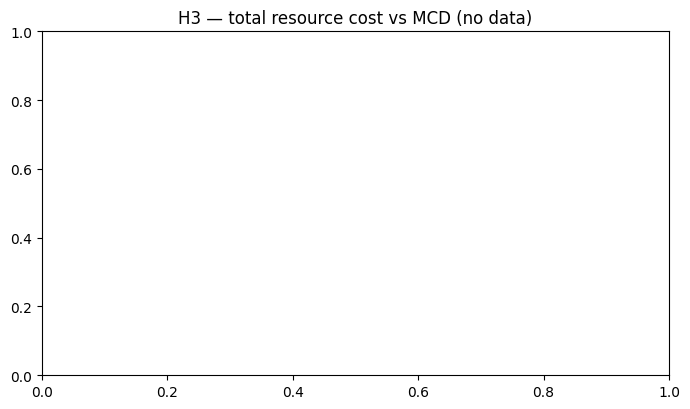

In [8]:
fig, ax = plt.subplots(figsize=(7,4.2))
line_by_arm(ax, "occ_ratio", "channel occupancy ratio (arm / none)",
            "H3 — total resource cost vs MCD", hline=1.0)
plt.tight_layout(); plt.show()

### Fig 4 — H4: distinct-L2ID trades the storm for RB collisions
Front-PRR degradation and the leader↔relay RB-overlap collision rate are the
cost that *replaces* the feedback storm.

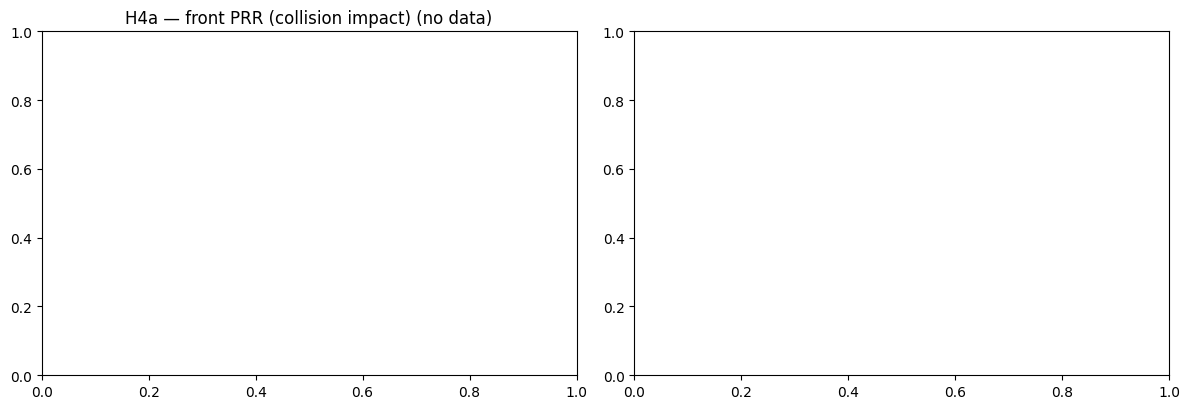

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12,4.2))
line_by_arm(axes[0], "prr_front", "front-segment PRR", "H4a — front PRR (collision impact)")
if not agg.empty:
    cr = (agg[agg.arm.isin(["sameL2","fixed","broadcast"])]
          .assign(lbl=lambda d: [arm_pos_label(a,r) for a,r in zip(d.arm,d.relayNode)])
          .groupby("lbl")["coll_rate"].mean().sort_values())
    if cr.notna().any():
        axes[1].bar(cr.index, cr.values)
    axes[1].set_ylabel("leader↔relay RB-collision rate")
    axes[1].set_title("H4b — collision rate by arm")
    axes[1].tick_params(axis="x", rotation=30)
    axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

### Fig 5 — the money plot: benefit vs cost
Each point is an arm (averaged over MCD ≤ 150 m, where the relay is meant to
operate). Up-and-left wins: more tail-PRR gain for less channel cost. An arm that
lands above `sameL2` and left of it dominates the storm design; one that also
reaches the `none_adapt` cost line beats single-hop MCS adaptation.

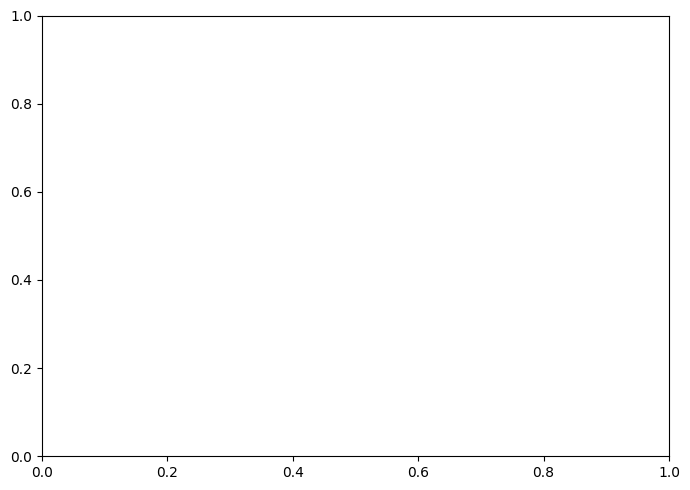

In [10]:
fig, ax = plt.subplots(figsize=(7,5))
if not agg.empty:
    lo = agg[agg.mcd <= 150]
    for a in ["sameL2", "fixed", "broadcast"]:
        for rn, g in lo[lo.arm == a].groupby("relayNode"):
            x = g.occ_ratio.mean(); y = g.d_prr_tail.mean()
            if np.isfinite(x) and np.isfinite(y):
                ax.scatter(x, y, s=90)
                ax.annotate(arm_pos_label(a, rn), (x, y),
                            textcoords="offset points", xytext=(6,4), fontsize=9)
    ax.axhline(0, ls="--", c="grey", lw=1)
    ax.set_xlabel("channel occupancy ratio vs none  (cost →)")
    ax.set_ylabel("Δ tail-PRR vs none  (benefit ↑)")
    ax.set_title("Benefit vs cost (MCD ≤ 150 m)"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Verdict table
Per arm (averaged over positions, operating points, and MCD ≤ 150 m). Flags are
**heuristic** guides, not the final word — read them with the figures.

In [11]:
def verdict():
    if agg.empty:
        return pd.DataFrame()
    lo = agg[agg.mcd <= 150]
    hi = agg[agg.mcd >= 300]
    out = []
    for a in ["sameL2", "fixed", "broadcast"]:
        g, gh = lo[lo.arm == a], hi[hi.arm == a]
        storm_hi = gh.storm_ratio_hop1.mean()
        rec = dict(
            arm=a,
            storm_ratio_hiMCD=round(float(storm_hi), 2),
            d_tail_PRR=round(float(g.d_prr_tail.mean()), 4),
            d_front_PRR=round(float(g.d_prr_front.mean()), 4),
            occ_ratio=round(float(g.occ_ratio.mean()), 2),
            coll_rate=round(float(g.coll_rate.mean()), 4),
            d_AoI_ms=round(float(g.d_aoi.mean()), 2),
            H1_no_storm=bool(storm_hi < 1.2),
            H2_tail_kept=bool(g.d_prr_tail.mean() >= 0),
            H3_cheaper_than_sameL2=None)
        out.append(rec)
    vt = pd.DataFrame(out)
    if "sameL2" in set(vt.arm):
        s_occ = float(vt.loc[vt.arm == "sameL2", "occ_ratio"].iloc[0])
        vt["H3_cheaper_than_sameL2"] = vt.occ_ratio < s_occ
    return vt

vt = verdict()
if not vt.empty:
    out_csv = (RESULTS_DIRS[0] if RESULTS_DIRS
               else os.path.expanduser("~"))
    vt.to_csv(os.path.join(out_csv, "l2id_compare_verdict.csv"), index=False)
vt

""


---
**Reading the result.** If `fixed` shows H1 (storm ratio ≈ 1 at high MCD), H2
(Δtail-PRR ≥ 0), H3 (occupancy < `sameL2`), and only mild H4 (small front-PRR
loss / low collision rate) — and on Fig 5 it sits at or left of `none_adapt`'s
cost — then distinct-L2ID strict-partition relaying **flips C4 into a positive
recommendation**. If instead H4 is severe (front-PRR collapses, high collision
rate) and cancels the tail gain, the honest conclusion stands: relaying loses to
worst-RX MCS adaptation regardless of L2ID design.

*Caveats:* effective-PRR denominator is the leader's generated CAM count;
collision rate needs the RB columns in `psschTxUeMac` (else shown as NaN);
heuristic flags are guides only. NR mode-2 SB-SPS throughout.